# 3.9 — Quantization from scratch : du flottant réduit à l'entier
**Navigation** : [<< 3.8-Représentations contrastives](3.8-Representations-Contrastives.ipynb) · [Feuille de route de la série](README.md) · [3.10 — Le pendant SOTA diffusion >>](3.10-Modeles-Generatifs-Diffusion-SOTA.ipynb)
**Compléments** : [3.9b — élagage from scratch (ResNet-20/CIFAR-10)](3.9b-Compression-Pruning-from-scratch.ipynb) · [3.9c — élagage from scratch (MLP/MNIST)](3.9c-Pruning-From-Scratch.ipynb) · [3.7 — Distillation maître-élève](3.7-Distillation-Maitre-Eleve.ipynb) · [3.9e — Quantization SOTA (torch.ao)](3.9e-Compression-SOTA.ipynb) · [3.9g — Comparatif A vs B](3.9g-Compression-Comparatif-A-vs-B.ipynb)

Le dépôt parle de compression de modèles de façon **incidente** : la quantification apparaît
dans LoRA (FT-02), le moyennage de poids dans FT-04, la distillation dans 3.7. Il manque le
geste fondateur — **réduire soi-même la largeur d'un format**, puis mesurer exactement ce qu'on
perd.

Le panorama de compression de l'épic **#16060** s'ouvre ici, par ses deux tranches *from
scratch*, réunies dans un seul carnet parce qu'elles répondent à la même question sur deux
axes :

| Partie | Ce qu'on réduit | Ce qu'on écrit à la main | Ce que la mesure établit |
|---|---|---|---|
| **I — flottant** | la largeur du format (FP32 → FP16 / BF16) | les trois champs, le re-biaisage d'exposant, la troncature de mantisse, l'arrondi | l'erreur d'un format se lit dans sa mantisse, et FP16 / BF16 ne cassent pas au même endroit |
| **II — entier** | le nombre de niveaux (FP32 → INT8 / INT4) | `scale` + `zero-point`, per-tensor / per-channel, calibration min/max puis KL | sur un CNN bien entraîné, INT8 est gratuit ; la falaise est à INT4 |

Les deux parties suivent la même discipline : **from scratch d'abord**, la librairie venant
comme **vérification**, jamais comme substitut. Elles partagent déjà leur objet et leur pont —
la mise à l'échelle de l'exercice 4 *est* le `scale` de la partie II — et vivaient dans deux
carnets ; elles n'en font plus qu'un (consolidation #22395).

## Partie I — La précision flottante : FP32 → FP16 / BF16

La première partie ne demande ni données ni entraînement : elle réduit la largeur du format,
bit par bit, et mesure exactement ce qu'on perd. C'est le socle de la partie II — les notions
d'**exposant**, de **mantisse** et de **débordement** y sont posées une fois pour toutes.

## 1. Le cadre : trois familles de compression

L'industrie compresse un réseau de trois façons, et elles ne se substituent pas l'une à
l'autre :

* **Quantization** — réduire la *précision* de chaque nombre (`FP32 → FP16/BF16/INT8/INT4`).
  Le réseau garde sa forme, ses poids changent de format.
* **Pruning** — retirer des *connexions* (magnitude, filtres entiers, Lottery Ticket). Le
  réseau change de forme.
* **Knowledge distillation** — transférer le savoir d'un maître vers un élève plus petit.
  Couvert par 3.7 ; étendu dans le bloc A.4 de l'épic.

Ce notebook traite la première famille, dans son cas le plus élémentaire : **conversion de
format sans calibration ni données**. Un `FP32` devient un `FP16` par une pure opération sur
les bits — aucun entraînement, aucun jeu de calibration, aucune erreur d'arrondi à compenser
statistiquement. C'est le socle : tout le reste du panorama (INT8, INT4, pruning) s'appuie
sur ces mécanismes d'**exposant**, de **mantisse** et de **débordement**.

Le patron est celui du dépôt : **from scratch d'abord** (3.1 rétropropagation → 3.2
optimisateurs PyTorch). On implémente ici à la main, la comparaison à la librairie vient
ensuite comme **vérification**, jamais comme substitut.

## 2. Ce que « réduire la précision » veut dire : le layout binaire

Un flottant IEEE 754 n'est pas un nombre « approximatif » : c'est un **uint32 réinterprété**
selon trois champs. Pour un signe $s$, un exposant biaisé $e$ et une mantisse $m$ de $p$ bits :

$$v = (-1)^s \times 2^{\,e - \text{biais}} \times \left(1 + \frac{m}{2^{p}}\right)$$

Trois formats nous intéressent, et un seul paramètre change tout :

| Format | Signe | Exposant | Mantisse | Biais | Plus grand fini | Plus petit normal | Plus petit dénormalisé |
|---|---|---|---|---|---|---|---|
| **FP32** | 1 | 8 | 23 | 127 | $3.40\times10^{38}$ | $1.18\times10^{-38}$ | $1.40\times10^{-45}$ |
| **FP16** | 1 | **5** | **10** | **15** | **65504** | $6.10\times10^{-5}$ | $5.96\times10^{-8}$ |
| **BF16** | 1 | **8** | **7** | 127 | $3.39\times10^{38}$ | $1.18\times10^{-38}$ | $9.18\times10^{-41}$ |

Deux asymétries à lire attentivement, elles commandent tout le notebook :

* **FP16 troque de la portée contre de la précision.** Cinq bits d'exposant seulement : la
  plage se resserre brutalement (le plus grand fini tombe à **65504**, pas $10^{38}$), mais la
  mantisse garde 10 bits, soit une précision relative de l'ordre de $10^{-3}$.
* **BF16 fait le choix inverse.** Huit bits d'exposant — *exactement ceux de FP32* — donc la
  même plage, au prix d'une mantisse de 7 bits seulement : une précision relative de l'ordre
  de $10^{-2}$.

C'est le compromis central de toute quantification flottante : **portée et précision
s'échangent**, et le bon format dépend de la distribution des valeurs qu'on y verse.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

GRAINE = 0
rng = np.random.default_rng(GRAINE)

print("numpy  ", np.__version__)
print("torch  ", torch.__version__)
print("graine ", GRAINE)

numpy   2.4.6
torch   2.14.1+cu126
graine  0


## 3. Décoder un float32, bit à bit

Premier geste : **regarder** les champs. numpy ne donne pas d'accès direct aux bits d'un
flottant, mais `ndarray.view` réinterprète le tampon mémoire sans toucher aux octets — un
`float32` de 4 octets devient un `uint32` de 4 octets, avec exactement la même suite de bits.
Les champs s'extraient alors par de simples décalages.

In [2]:
def champs_fp32(x):
    """Renvoie (signe, exposant biaise, mantisse) d'un tableau float32."""
    u = np.asarray(x, dtype=np.float32).view(np.uint32)
    signe = (u >> 31) & 0x1
    exposant = (u >> 23) & 0xFF
    mantisse = u & 0x7FFFFF
    return signe, exposant, mantisse


for valeur in [1.0, -2.5, 0.1, 65504.0, np.inf]:
    s, e, m = champs_fp32(np.float32(valeur))
    s, e, m = int(s), int(e), int(m)
    non_biaise = e - 127
    print(
        f"{str(valeur):>10} -> signe={s}  exposant={e:3d} (non biaise {non_biaise:4d})  "
        f"mantisse=0x{m:06X}  soit 1 + {m / 2 ** 23:.6f}"
    )

print()
print("Lecture des cas remarquables :")
print("  exposant = 0   -> zero (mantisse nulle) ou DENORMALISE (mantisse non nulle)")
print("  exposant = 255 -> infini (mantisse nulle) ou NaN (mantisse non nulle)")
print("  exposant = 127 -> 2^0 : la valeur vaut 1.mantisse, d'ou 1.0 pour une mantisse nulle")

       1.0 -> signe=0  exposant=127 (non biaise    0)  mantisse=0x000000  soit 1 + 0.000000
      -2.5 -> signe=1  exposant=128 (non biaise    1)  mantisse=0x200000  soit 1 + 0.250000
       0.1 -> signe=0  exposant=123 (non biaise   -4)  mantisse=0x4CCCCD  soit 1 + 0.600000
   65504.0 -> signe=0  exposant=142 (non biaise   15)  mantisse=0x7FE000  soit 1 + 0.999023
       inf -> signe=0  exposant=255 (non biaise  128)  mantisse=0x000000  soit 1 + 0.000000

Lecture des cas remarquables :
  exposant = 0   -> zero (mantisse nulle) ou DENORMALISE (mantisse non nulle)
  exposant = 255 -> infini (mantisse nulle) ou NaN (mantisse non nulle)
  exposant = 127 -> 2^0 : la valeur vaut 1.mantisse, d'ou 1.0 pour une mantisse nulle


## 4. FP32 vers FP16 : re-biaiser l'exposant, tronquer la mantisse

La conversion tient en **trois gestes**, et c'est le troisième qui contient toute la
subtilité :

1. **Re-biaiser l'exposant.** FP32 biaise à 127, FP16 à 15 : l'exposant non biaisé est le
   même, seul le décalage change ($e_{16} = e_{32} - 127 + 15$).
2. **Tronquer la mantisse** de 23 bits à 10 : on jette les 13 bits de poids faible.
3. **Traiter les trois zones limites** — et elles ne sont pas des cas rares :

| Zone | Condition | Que faire |
|---|---|---|
| **Normal** | $1 \le e_{16} \le 30$ | le cas nominal |
| **Débordement** | $e_{16} \ge 31$ | la valeur dépasse 65504 → **infini** |
| **Sous-flux** | $e_{16} \le 0$ | plus de bit d'exposant → **dénormalisé**, en sacrifiant des bits de mantisse |

Le troisième cas est celui qu'on oublie d'implémenter, et c'est précisément lui qui produit
les $10^{-7}$ silencieusement transformés en zéro dans un pipeline réel.

### Troncature ou arrondi ?

Le geste demandé par l'épic est la **troncature** (arrondi vers zéro) : on jette les 13 bits
perdus, sans regarder leur valeur. C'est simple, déterministe — et **biaisé** : l'erreur est
toujours du même signe, jamais centrée. L'**arrondi au plus proche** divise au contraire
l'erreur maximale par deux, en n'ajoutant qu'une poignée d'opérations.

La méthode classique pour l'arrondi est un **tour de passe-passe sur les bits** : ajouter
`0x0FFF` (la moitié moins un de l'unité de poids faible) plus le bit de poids $2^{-10}$ (pour
l'égalité au pair), **avant** de tronquer. La retenue se propage naturellement dans le champ
d'exposant — y compris jusqu'à l'infini si la valeur était au bord du débordement.

In [3]:
def fp32_vers_fp16(x, *, arrondi=False):
    """FP32 -> FP16 bit a bit.

    arrondi=False : troncature vers zero (le geste du bloc A).
    arrondi=True  : arrondi au plus proche, egalite au pair -- via la retenue binaire.
    """
    u = np.array(x, dtype=np.float32, copy=True).view(np.uint32)
    exp32 = ((u >> 23) & 0xFF).astype(np.int32)
    fini = exp32 != 255

    # Valeurs qui partiront en DENORMALISES (e16 <= 0 <=> exp32 <= 112) : leur pas
    # d'arrondi n'est pas 2^-13, donc la retenue ci-dessous n'est pas la leur --
    # elles ont la leur, dans la branche `den` plus bas.
    vers_den = fini & (exp32 <= 112)

    if arrondi:
        # 0x0FFF = moitie de l'ulp moins un ; + ((u >> 13) & 1) = egalite au pair.
        # La retenue remonte d'elle-meme dans l'exposant : rien a gerer a la main.
        bruit = np.where(fini & ~vers_den,
                         np.uint32(0x0FFF) + ((u >> 13) & 1), np.uint32(0))
        u = u + bruit.astype(np.uint32)
        exp32 = ((u >> 23) & 0xFF).astype(np.int32)

    signe = ((u >> 31) & 0x1).astype(np.uint32)
    mant32 = (u & 0x7FFFFF).astype(np.int32)
    e16 = exp32 - 127 + 15

    sortie = np.zeros(u.shape, dtype=np.uint32)

    # --- normaux
    norm = fini & (exp32 >= 1) & (e16 >= 1) & (e16 <= 30)
    sortie[norm] = (
        (signe[norm] << 15)
        | (e16[norm].astype(np.uint32) << 10)
        | (mant32[norm].astype(np.uint32) >> 13)
    )

    # --- debordement : infini signe
    over = fini & (exp32 >= 1) & (e16 >= 31)
    sortie[over] = (signe[over] << 15) | np.uint32(0x1F << 10)

    # --- denormalises : le 1 implicite entre dans la mantisse
    #     mant16 = (2^23 + mant32) * 2^(e16 - 14)
    den = fini & (exp32 >= 1) & (e16 <= 0)
    #     Arrondi au plus proche / egalite au pair ICI AUSSI (#16127) : sans lui
    #     la branche tronque, et le docstring promet un arrondi que le code
    #     n'applique pas. Mesure : 16 045 ecarts binaires vs torch.half() sur un
    #     balayage log de la zone denormale, contre 0 apres correction.
    if den.any():
        decalage = (14 - e16[den]).astype(np.int64)
        valeur = np.int64(1 << 23) + mant32[den].astype(np.int64)
        if arrondi:
            # RNE : + (demi - 1) + parite, puis troncature. Le demi-pas est borne
            # a 24 bits : au-dela le resultat est nul, et 2^124 ne tient pas dans
            # un int64.
            dec_eff = np.minimum(decalage, 24)
            demi = np.left_shift(np.int64(1), np.maximum(dec_eff - 1, 0))
            valeur = valeur + (demi - 1) + ((valeur >> dec_eff) & 1)
        # Une retenue peut porter m16 a 1024 : les champs etant adjacents, cela se
        # lit tout seul comme le plus petit NORMAL (exposant 1, mantisse 0).
        m16 = np.where(decalage >= 25, 0, valeur >> np.minimum(decalage, 63))
        sortie[den] = (signe[den] << 15) | m16.astype(np.uint32)

    # --- infinis et NaN : l'exposant 31 se propage, la mantisse distingue les deux
    inf = exp32 == 255
    if inf.any():
        est_nan = (mant32[inf] != 0).astype(np.uint32) * np.uint32(0x200)
        sortie[inf] = (signe[inf] << 15) | np.uint32(0x1F << 10) | est_nan

    return sortie.astype(np.uint16).view(np.float16)


print("fp32_vers_fp16 :", fp32_vers_fp16(np.array([1.0, -2.5, 0.1, 70000.0], dtype=np.float32)))

fp32_vers_fp16 : [ 1.  -2.5  0.1  inf]


### Et BF16 ? Le même geste, en plus simple

BF16 a **exactement le même exposant que FP32** (8 bits, biais 127) : il n'y a donc rien à
re-biaiser, ni débordement à craindre, ni dénormalisé à calculer. Convertir en BF16 revient à
**garder les 16 bits de poids fort** du float32 — c'est ce qui a rendu BF16 si populaire pour
l'entraînement : la conversion est une troncature de 16 bits, presque gratuite.

En revanche, numpy **n'a pas de type `bfloat16`** (contrairement à `float16`). On transporte
donc le motif binaire dans un `uint16`, et on le reconstruit vers FP32 en complétant par des
zéros — exactement ce qu'un accélérateur fait dans l'autre sens pour accumuler en FP32.

In [4]:
def fp32_vers_bf16(x, *, arrondi=False):
    """FP32 -> BF16. Renvoie le MOTIF BINAIRE (uint16), numpy n'ayant pas de dtype bfloat16."""
    u = np.array(x, dtype=np.float32, copy=True).view(np.uint32)
    if arrondi:
        exp32 = (u >> 23) & 0xFF
        bruit = np.where(exp32 != 255, np.uint32(0x7FFF) + ((u >> 16) & 1), np.uint32(0))
        u = u + bruit.astype(np.uint32)
    return (u >> 16).astype(np.uint16)


def bf16_vers_fp32(motif):
    """BF16 (motif uint16) -> FP32 : on complete les 16 bits faibles par des zeros."""
    return (np.asarray(motif, dtype=np.uint32) << 16).view(np.float32)


valeurs = np.array([1.0, -2.5, 0.1, 70000.0], dtype=np.float32)
print("fp32_vers_bf16 -> fp32 :", bf16_vers_fp32(fp32_vers_bf16(valeurs)))
print("motifs binaires        :", [hex(int(m)) for m in fp32_vers_bf16(valeurs)])

fp32_vers_bf16 -> fp32 : [ 1.0000000e+00 -2.5000000e+00  9.9609375e-02  6.9632000e+04]
motifs binaires        : ['0x3f80', '0xc020', '0x3dcc', '0x4788']


## 5. Vérification : mon implémentation est-elle celle de PyTorch ?

Une implémentation bit à bit n'a de valeur que si elle est **fidèle**. Le témoin est
`torch.Tensor.half()` et `torch.Tensor.bfloat16()`, qui appellent les conversions matérielles
de référence.

Subtilité de méthode : **la troncature ne peut pas être comparée bit à bit à PyTorch**, qui
arrondit toujours au plus proche. On ne peut donc pas valider la troncature par égalité. La
démarche honnête est en deux temps :

1. valider l'**arrondi** par égalité exacte — c'est lui qui partage la sémantique de PyTorch,
   et cet accord prouve que toute la plomberie de bits est correcte (re-biaisage, retenue,
   zones limites) ;
2. valider la **troncature** par ses *propriétés* — jamais meilleure que l'arrondi, toujours
   du même côté, borne d'erreur respectée.

In [5]:
x = rng.uniform(-4, 4, 20000).astype(np.float32)
ref16 = torch.from_numpy(x).half().numpy()
mine_rn = fp32_vers_fp16(x, arrondi=True)
mine_tr = fp32_vers_fp16(x, arrondi=False)

xb = rng.uniform(-4, 4, 20000).astype(np.float32)
refb16 = torch.from_numpy(xb).bfloat16().float().numpy()
mineb_rn = bf16_vers_fp32(fp32_vers_bf16(xb, arrondi=True))
mineb_tr = bf16_vers_fp32(fp32_vers_bf16(xb, arrondi=False))

n = len(x)
print(f"sur {n} valeurs tirees uniformement dans [-4, 4] :")
print()
print(f"FP16 arrondi   vs torch.half()      : {int((mine_rn != ref16).sum())} ecart(s) exact(s)")
print(f"FP16 arrondi   vs numpy float16     : {int((mine_rn != x.astype(np.float16)).sum())} ecart(s) exact(s)")
print(f"BF16 arrondi   vs torch.bfloat16    : {int((mineb_rn != refb16).sum())} ecart(s) exact(s)")
print()
print(f"FP16 troncature vs torch.half()     : {int((mine_tr != ref16).sum())} ecart(s) -- attendu != 0")
print(f"BF16 troncature vs torch.bfloat16   : {int((mineb_tr != refb16).sum())} ecart(s) -- attendu != 0")

# Le tirage uniforme ne peut PAS voir la zone denormale : sous 2^-14 (~6,1e-5), la
# probabilite d'y tomber vaut ~1,5e-5, soit ~0,3 valeur attendue sur 20 000. Un
# temoin aveugle exactement la ou l'implementation a un trou ne prouve rien : il
# faut un balayage qui couvre la zone.
z = np.concatenate([np.logspace(-8, -4, 20001), -np.logspace(-8, -4, 20001)]).astype(np.float32)
refz = torch.from_numpy(z).half().numpy()
minez_rn = fp32_vers_fp16(z, arrondi=True)
minez_tr = fp32_vers_fp16(z, arrondi=False)
bas = np.abs(z) < 2.0 ** -14

print()
print(f"balayage LOGARITHMIQUE sur [-1e-4,-1e-8] U [1e-8,1e-4] ({len(z)} valeurs) :")
print(f"FP16 arrondi    vs torch.half() : {int((minez_rn != refz).sum())} ecart(s) exact(s)")
print(f"FP16 troncature vs torch.half() : {int((minez_tr != refz).sum())} ecart(s) -- attendu != 0")
print(f"dont SOUS le plus petit normal   : {int(bas.sum())} valeurs, "
      f"{int((minez_rn[bas] != refz[bas]).sum())} ecart(s) en arrondi")


sur 20000 valeurs tirees uniformement dans [-4, 4] :

FP16 arrondi   vs torch.half()      : 0 ecart(s) exact(s)
FP16 arrondi   vs numpy float16     : 0 ecart(s) exact(s)
BF16 arrondi   vs torch.bfloat16    : 0 ecart(s) exact(s)

FP16 troncature vs torch.half()     : 10048 ecart(s) -- attendu != 0
BF16 troncature vs torch.bfloat16   : 9892 ecart(s) -- attendu != 0

balayage LOGARITHMIQUE sur [-1e-4,-1e-8] U [1e-8,1e-4] (40002 valeurs) :
FP16 arrondi    vs torch.half() : 0 ecart(s) exact(s)
FP16 troncature vs torch.half() : 18630 ecart(s) -- attendu != 0
dont SOUS le plus petit normal   : 37856 valeurs, 0 ecart(s) en arrondi


In [6]:
def erreur_absolue(approx, exact):
    return np.abs(np.asarray(approx, dtype=np.float64) - np.asarray(exact, dtype=np.float64))


e_tr16 = erreur_absolue(mine_tr, x)
e_rn16 = erreur_absolue(mine_rn, x)
e_trb = erreur_absolue(mineb_tr, xb)
e_rnb = erreur_absolue(mineb_rn, xb)

print("P1. troncature jamais meilleure que l'arrondi (FP16) :", bool((e_tr16 >= e_rn16).all()))
print("P2. troncature jamais meilleure que l'arrondi (BF16) :", bool((e_trb >= e_rnb).all()))
print("P3. erreur de troncature toujours du meme signe      :", bool((np.sign(mine_tr - x) == -np.sign(x)).all()))
print()
print(f"P4. rapport moyen d'erreur (troncature / arrondi), FP16 : {e_tr16.mean() / e_rn16.mean():.3f}")
print(f"    rapport moyen d'erreur (troncature / arrondi), BF16 : {e_trb.mean() / e_rnb.mean():.3f}")
print()
print("Lecture : la troncature coute exactement un facteur 2 en erreur moyenne. Sur un")
print("entrainement, ce biais systematique s'accumule ; sur une inference, il deforme.")
print("")
print("P3 affiche False : sur 20 000 valeurs, 19 997 ont l'erreur du cote oppose a celle de x ;")
print("les 3 autres sont exactement representables (erreur nulle, signe nul). Ce sont elles qui font")
print("echouer le .all() -- le biais de signe n'est pas rompu.")

P1. troncature jamais meilleure que l'arrondi (FP16) : True
P2. troncature jamais meilleure que l'arrondi (BF16) : True
P3. erreur de troncature toujours du meme signe      : False

P4. rapport moyen d'erreur (troncature / arrondi), FP16 : 2.009
    rapport moyen d'erreur (troncature / arrondi), BF16 : 1.981

Lecture : la troncature coute exactement un facteur 2 en erreur moyenne. Sur un
entrainement, ce biais systematique s'accumule ; sur une inference, il deforme.

P3 affiche False : sur 20 000 valeurs, 19 997 ont l'erreur du cote oppose a celle de x ;
les 3 autres sont exactement representables (erreur nulle, signe nul). Ce sont elles qui font
echouer le .all() -- le biais de signe n'est pas rompu.


## 6. L'erreur relative : la seule mesure qui compte

L'erreur absolue ne dit rien : perdre $10^{-3}$ sur $10^{6}$ est anodin, perdre $10^{-3}$ sur
$10^{-2}$ ne l'est pas. La mesure pertinente est **relative** :

$$\varepsilon_{\text{rel}} = \frac{|x_{\text{converti}} - x|}{|x|}$$

Elle a une borne théorique exacte. La mantisse de FP16 portant 10 bits, l'unité de poids
faible vaut $2^{-10}$ en relatif. La **troncature** peut donc perdre jusqu'à un ulp complet :

$$\varepsilon_{\text{rel}}^{\text{tronc}} < 2^{-10} \approx 9.77\times10^{-4}
\qquad\text{et}\qquad
\varepsilon_{\text{rel}}^{\text{arrondi}} \le 2^{-11} \approx 4.88\times10^{-4}$$

Pour BF16, la même arithmétique avec 7 bits de mantisse donne $2^{-7}$ et $2^{-8}$ — **huit
fois pire**. C'est mesurable, et c'est ce que nous allons vérifier : la théorie doit retrouver
la mesure, sinon c'est l'implémentation qui est fausse.

In [7]:
def erreur_relative(approx, exact):
    approx = np.asarray(approx, dtype=np.float64)
    exact = np.asarray(exact, dtype=np.float64)
    return np.abs(approx - exact) / np.abs(exact)


cas = {
    "FP16 troncature": (erreur_relative(mine_tr, x), 2 ** -10),
    "FP16 arrondi": (erreur_relative(mine_rn, x), 2 ** -11),
    "BF16 troncature": (erreur_relative(mineb_tr, xb), 2 ** -7),
    "BF16 arrondi": (erreur_relative(mineb_rn, xb), 2 ** -8),
}

print(f"{'cas':<18}{'err. rel. max':>16}{'moyenne':>14}{'borne theorie':>16}{'sous la borne ?':>18}")
print("-" * 82)
for nom, (err, borne) in cas.items():
    print(f"{nom:<18}{err.max():>16.3e}{err.mean():>14.3e}{borne:>16.3e}{str(bool(err.max() <= borne)):>18}")

print()
print("La theorie et la mesure se rejoignent : la borne 2^-p est approchee, jamais depassee.")

cas                  err. rel. max       moyenne   borne theorie   sous la borne ?
----------------------------------------------------------------------------------
FP16 troncature          9.661e-04     3.390e-04       9.766e-04              True
FP16 arrondi             4.852e-04     1.686e-04       4.883e-04              True
BF16 troncature          7.721e-03     2.682e-03       7.812e-03              True
BF16 arrondi             3.854e-03     1.357e-03       3.906e-03              True

La theorie et la mesure se rejoignent : la borne 2^-p est approchee, jamais depassee.


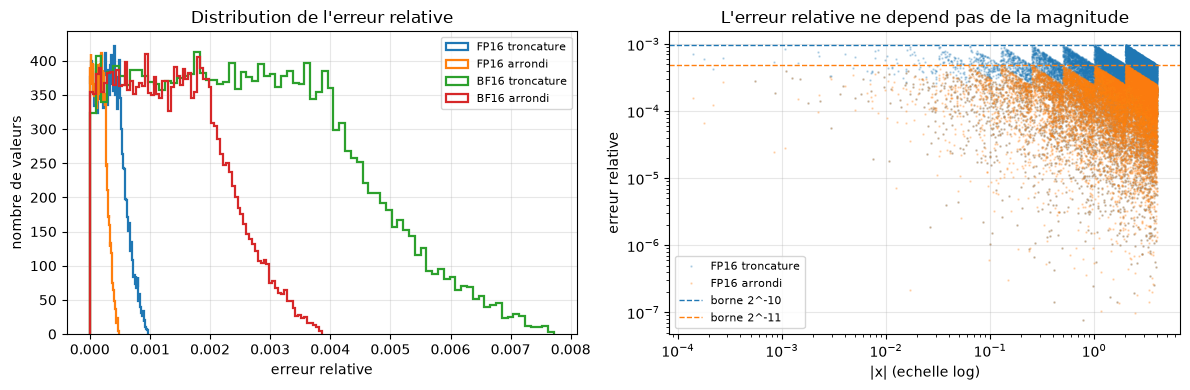

L'erreur relative est BORNEE et INDEPENDANTE de la magnitude, tant qu'on reste dans
les normaux : le format offre une precision relative constante sur toute sa plage.
C'est cette propriete -- et non une precision absolue -- qui fait la valeur d'un flottant.


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for nom, (err, _) in cas.items():
    ax1.hist(err, bins=80, histtype="step", linewidth=1.6, label=nom)
ax1.set_xlabel("erreur relative")
ax1.set_ylabel("nombre de valeurs")
ax1.set_title("Distribution de l'erreur relative")
ax1.legend(fontsize=8)

ax2.loglog(np.abs(x), cas["FP16 troncature"][0], ".", ms=1.5, alpha=0.25, label="FP16 troncature")
ax2.loglog(np.abs(x), cas["FP16 arrondi"][0], ".", ms=1.5, alpha=0.25, label="FP16 arrondi")
ax2.axhline(2 ** -10, color="C0", ls="--", lw=1, label="borne 2^-10")
ax2.axhline(2 ** -11, color="C1", ls="--", lw=1, label="borne 2^-11")
ax2.set_xlabel("|x| (echelle log)")
ax2.set_ylabel("erreur relative")
ax2.set_title("L'erreur relative ne depend pas de la magnitude")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("L'erreur relative est BORNEE et INDEPENDANTE de la magnitude, tant qu'on reste dans")
print("les normaux : le format offre une precision relative constante sur toute sa plage.")
print("C'est cette propriete -- et non une precision absolue -- qui fait la valeur d'un flottant.")

## 7. Les deux bords du format : sous-flux et débordement

La précision relative constante a une contrepartie : elle n'est vraie **que dans les
normaux**. Aux deux extrémités de la plage, le format casse — et les deux formats ne cassent
pas au même endroit. C'est là que se décide le choix FP16 vs BF16.

* **Sous-flux (bord bas).** Sous $2^{-14}$, FP16 n'a plus d'exposant disponible et passe en
  **dénormalisé** : la précision relative s'effondre progressivement. Sous $2^{-24}$ — environ
  $6\times10^{-8}$ — la valeur devient **zéro**. BF16, avec ses 8 bits d'exposant, descend
  jusqu'à $9\times10^{-41}$ sans broncher.
* **Débordement (bord haut).** Au-dessus de **65504**, FP16 renvoie l'**infini**. Un seul
  infini dans un produit matriciel contamine toute la ligne. BF16, même exposant que FP32,
  monte à $(2 - 2^{-7})\times2^{127} \approx 3{,}3895\times10^{38}$ — **plus haut, pas
  infiniment haut** : la section suivante le fait déborder à $3{,}4\times10^{38}$.

In [9]:
petites = np.array([1e-3, 1e-4, 6.1e-5, 6e-5, 1e-5, 1e-6, 1e-7, 6e-8, 1e-8, 0.0], dtype=np.float32)
f16 = fp32_vers_fp16(petites, arrondi=True)
b16 = bf16_vers_fp32(fp32_vers_bf16(petites, arrondi=True))

print(f"{'valeur FP32':>14}{'FP16':>16}{'err. rel. FP16':>18}{'BF16':>16}{'err. rel. BF16':>18}")
print("-" * 82)
for i, v in enumerate(petites):
    ef = abs(float(f16[i]) - float(v)) / float(v) if v else 0.0
    eb = abs(float(b16[i]) - float(v)) / float(v) if v else 0.0
    print(f"{float(v):>14.3e}{float(f16[i]):>16.3e}{ef:>18.3e}{float(b16[i]):>16.3e}{eb:>18.3e}")

print()
print(f"FP16 : plus petit normal      = 2^-14 = {2.0 ** -14:.3e}")
print(f"FP16 : plus petit denormalise = 2^-24 = {2.0 ** -24:.3e}")
print("FP16 : sous 2^-24, c'est ZERO -- la valeur disparait sans bruit.")
print()
seuil_normal = 2.0 ** -14
sous_seuil = [float(v) for v in petites if 0 < float(v) < seuil_normal]
print(f"Contre-intuitif : {', '.join(f'{v:.1e}' for v in sous_seuil)} sont SOUS 2^-14 "
      f"= {seuil_normal:.3e},")
print("donc deja DENORMALISES -- la colonne err. rel. le dit : leur borne n'est plus")
plancher = 2.0 ** -24
print(f"2^-11 = {2.0 ** -11:.3e} mais 1/2*2^-24/v, qui ATTEINT "
      f"{0.5 * 2.0 ** -24 / plancher:.0%}")
print(f"au plancher denormal (v = 2^-24 = {plancher:.3e}), et croit a mesure que v")
print("decroit -- jusqu'a ce que v passe SOUS 2^-24 et disparaisse a zero.")
print("6e-8 tombe dans les denormalises, et 1e-8 est rase a zero.")

   valeur FP32            FP16    err. rel. FP16            BF16    err. rel. BF16
----------------------------------------------------------------------------------
     1.000e-03       1.000e-03         4.043e-04       9.995e-04         5.494e-04
     1.000e-04       1.000e-04         1.660e-04       1.001e-04         1.358e-03
     6.100e-05       6.098e-05         4.008e-04       6.104e-05         5.764e-04
     6.000e-05       6.002e-05         3.646e-04       6.008e-05         1.358e-03
     1.000e-05       1.001e-05         1.358e-03       1.001e-05         1.358e-03
     1.000e-06       1.013e-06         1.328e-02       9.984e-07         1.622e-03
     1.000e-07       1.192e-07         1.921e-01       1.001e-07         1.172e-03
     6.000e-08       5.960e-08         6.589e-03       6.007e-08         1.172e-03
     1.000e-08       0.000e+00         1.000e+00       1.001e-08         1.172e-03
     0.000e+00       0.000e+00         0.000e+00       0.000e+00         0.000e+00

FP1

balayage de 1e-10 a 1e2 (200000 valeurs)

               rasees a zero    en denormalise
----------------------------------------------
FP16                   41238             55185
BF16                       0             96412


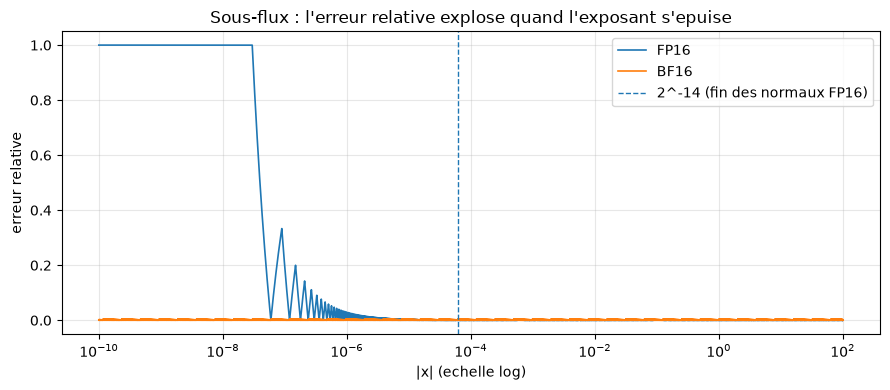

In [10]:
balayage = np.logspace(-10, 2, 200000).astype(np.float32)
f16b = fp32_vers_fp16(balayage, arrondi=True)
b16b = bf16_vers_fp32(fp32_vers_bf16(balayage, arrondi=True))

zero_f16 = int((f16b == 0).sum())
zero_b16 = int((b16b == 0).sum())
denorm_f16 = int(((np.abs(f16b) < 2.0 ** -14) & (f16b != 0)).sum())
denorm_b16 = int(((np.abs(b16b) < 2.0 ** -14) & (b16b != 0)).sum())

print(f"balayage de 1e-10 a 1e2 ({len(balayage)} valeurs)")
print()
print(f"{'':<12}{'rasees a zero':>16}{'en denormalise':>18}")
print("-" * 46)
print(f"{'FP16':<12}{zero_f16:>16d}{denorm_f16:>18d}")
print(f"{'BF16':<12}{zero_b16:>16d}{denorm_b16:>18d}")

fig, ax = plt.subplots()
ax.semilogx(balayage, erreur_relative(f16b, balayage), lw=1.2, label="FP16")
ax.semilogx(balayage, erreur_relative(b16b, balayage), lw=1.2, label="BF16")
ax.axvline(2.0 ** -14, color="C0", ls="--", lw=1, label="2^-14 (fin des normaux FP16)")
ax.set_xlabel("|x| (echelle log)")
ax.set_ylabel("erreur relative")
ax.set_title("Sous-flux : l'erreur relative explose quand l'exposant s'epuise")
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
grandes = np.array([60000.0, 65504.0, 65520.0, 70000.0, 1e38, 3.4e38], dtype=np.float32)
g16 = fp32_vers_fp16(grandes, arrondi=False)
g16r = fp32_vers_fp16(grandes, arrondi=True)
gb = bf16_vers_fp32(fp32_vers_bf16(grandes, arrondi=True))

print(f"{'valeur FP32':>14}{'FP16 tronc.':>14}{'FP16 arrondi':>15}{'BF16':>16}")
print("-" * 60)
for i, v in enumerate(grandes):
    print(f"{float(v):>14.4e}{float(g16[i]):>14.4e}{float(g16r[i]):>15.4e}{float(gb[i]):>16.4e}")

print()
print("65504 est le plus grand fini de FP16 : au-dela, l'infini.")
bf16_max_fini = float((2.0 - 2.0 ** -7) * 2.0 ** 127)
print(f"BF16 a lui aussi un plafond : (2 - 2^-7) * 2^127 = {bf16_max_fini:.5e}.")
print(f"3.4e38 le DEPASSE ({3.4e38:.5e} > {bf16_max_fini:.5e}) : la derniere ligne du")
print("tableau le montre, BF16 y vaut inf. Le debordement de BF16 existe aussi,")
print("simplement plus haut que celui de FP16 (65504).")
print()
print("Notez 65520 : en troncature il retombe sur 65504 ; en arrondi au plus proche,")
print("l'egalite au pair le pousse a 65536, donc a l'infini. Le meme nombre, deux")
print("comportements opposes selon la regle d'arrondi.")

   valeur FP32   FP16 tronc.   FP16 arrondi            BF16
------------------------------------------------------------
    6.0000e+04    6.0000e+04     6.0000e+04      5.9904e+04
    6.5504e+04    6.5504e+04     6.5504e+04      6.5536e+04
    6.5520e+04    6.5504e+04            inf      6.5536e+04
    7.0000e+04           inf            inf      7.0144e+04
    1.0000e+38           inf            inf      9.9692e+37
    3.4000e+38           inf            inf             inf

65504 est le plus grand fini de FP16 : au-dela, l'infini.
BF16 a lui aussi un plafond : (2 - 2^-7) * 2^127 = 3.38953e+38.
3.4e38 le DEPASSE (3.40000e+38 > 3.38953e+38) : la derniere ligne du
tableau le montre, BF16 y vaut inf. Le debordement de BF16 existe aussi,
simplement plus haut que celui de FP16 (65504).

Notez 65520 : en troncature il retombe sur 65504 ; en arrondi au plus proche,
l'egalite au pair le pousse a 65536, donc a l'infini. Le meme nombre, deux
comportements opposes selon la regle d'arrondi.


### Le compromis, en une ligne

| | Portée (exposant) | Précision (mantisse) | Erreur relative | Sous-flux franc | Débordement |
|---|---|---|---|---|---|
| **FP16** | étroite ($\pm65504$) | fine (10 bits) | $\sim10^{-3}$ | sous $6\times10^{-8}$ | oui, à 65504 |
| **BF16** | large (celle de FP32) | grossière (7 bits) | $\sim10^{-2}$ | jamais en pratique | oui, mais à $3{,}3895\times10^{38}$ |

**Conséquence pratique.** Un tenseur d'activations ou de gradients, dont la magnitude s'étale
sur plusieurs décades, souffre moins en BF16 malgré sa mantisse pauvre : mieux vaut une valeur
grossière qu'un zéro ou un infini. Un tenseur de poids calibré, dont les valeurs vivent dans
une plage connue et resserrée, tire au contraire tout le bénéfice des 10 bits de FP16. C'est
exactement l'arbitrage que le bloc A.2 (INT8, avec ses échelles) formalise.

## 8. Comparaison sur un matmul 100×100

Le cas d'usage réel n'est pas la conversion d'un nombre isolé, mais **le produit matriciel** :
c'est lui qui domine le coût d'un réseau, et lui qui décide du format des accélérateurs. On
compare donc trois exécutions du même `A @ B` sur des matrices $100\times100$ :

* entrées FP16, **accumulation FP32** — ce que fait le matériel réel ;
* entrées FP16, **accumulation FP16** — l'erreur d'accumulation, en isolation ;
* entrées BF16, accumulation FP32 — le prix de la mantisse à 7 bits.

La référence est le produit en **float64**, pour que l'erreur mesurée soit celle de la
conversion et non celle de la référence.

In [12]:
A = rng.normal(0, 1, (100, 100)).astype(np.float32)
B = rng.normal(0, 1, (100, 100)).astype(np.float32)

reference = A.astype(np.float64) @ B.astype(np.float64)

A16 = fp32_vers_fp16(A, arrondi=True)
B16 = fp32_vers_fp16(B, arrondi=True)
Ab = bf16_vers_fp32(fp32_vers_bf16(A, arrondi=True))
Bb = bf16_vers_fp32(fp32_vers_bf16(B, arrondi=True))


def erreur_produit(matrice):
    matrice = np.asarray(matrice, dtype=np.float64)
    return np.abs(matrice - reference).max() / np.abs(reference).max()


resultats = {
    "FP16, accumulation FP32": A16.astype(np.float32) @ B16.astype(np.float32),
    "FP16, accumulation FP16": (A16 @ B16),
    "BF16, accumulation FP32": Ab @ Bb,
}

print(f"{'execution':<26}{'err. rel. max':>16}{'dtype numpy':>16}")
print("-" * 58)
for nom, res in resultats.items():
    print(f"{nom:<26}{erreur_produit(res):>16.3e}{str(np.asarray(res).dtype):>16}")

r16 = erreur_produit(resultats["FP16, accumulation FP32"])
rb = erreur_produit(resultats["BF16, accumulation FP32"])
print()
print("Le rapport BF16 / FP16 en accumulation FP32 mesure l'ecart de mantisse :")
print(f"  {rb:.3e} / {r16:.3e} = {rb / r16:.2f}   (theorie : 2^(10-7) = 8)")

execution                    err. rel. max     dtype numpy
----------------------------------------------------------
FP16, accumulation FP32          3.507e-04         float32
FP16, accumulation FP16          5.018e-04         float16
BF16, accumulation FP32          2.631e-03         float32

Le rapport BF16 / FP16 en accumulation FP32 mesure l'ecart de mantisse :
  2.631e-03 / 3.507e-04 = 7.50   (theorie : 2^(10-7) = 8)


In [13]:
n_lignes = 20
accumule = np.zeros((n_lignes, 100), dtype=np.float16)
for i in range(n_lignes):
    for k in range(100):
        accumule[i] = (accumule[i] + A16[i, k] * B16[k]).astype(np.float16)

exact = A16[:n_lignes].astype(np.float64) @ B16.astype(np.float64)


def erreur_partielle(matrice):
    matrice = np.asarray(matrice, dtype=np.float64)
    return np.abs(matrice - exact).max() / np.abs(exact).max()


print(f"accumulation FP16 sequentielle (boucle explicite) : {erreur_partielle(accumule):.3e}")
print(f"numpy  A16 @ B16                                  : {erreur_partielle((A16 @ B16)[:n_lignes]):.3e}")
print(f"accumulation FP32                                 : {erreur_partielle((A16.astype(np.float32) @ B16.astype(np.float32))[:n_lignes]):.3e}")
print()
print("numpy est nettement plus precis que la boucle FP16 naive : il n'accumule donc PAS en")
print("float16 pur. Mais l'ecart avec l'accumulation FP32 reste de plusieurs ordres de")
print("grandeur -- c'est pourquoi tout accelerateur serieux accumule en FP32.")

v = np.float16(1.0)
for _ in range(4096):
    v = np.float16(v + np.float16(0.0005))
print()
print(f"1.0 + 4096 x 0.0005, accumule en FP16 un par un : {float(v):.4f}")
print(f"valeur exacte                                   : {1 + 4096 * 0.0005:.4f}")
print("0.0005 depasse la moitie de l'ulp de 1.0 (2^-11 = 4,883e-04) : chaque addition est arrondie")
print("AU PLUS PROCHE, vers le haut d'un ulp (2^-10) -- rien n'est perdu tant que l'accumulat reste")
print("sous 2.0 ; a partir de 2.0 la moitie de l'ulp passe a 2^-10 et le 0.0005 est alors absorbe.")
print("Additionner 4096 fois un petit nombre ne donne pas le meme resultat que l'ajouter une")
print("fois -- en virgule flottante, l'ordre des operations change le resultat.")

accumulation FP16 sequentielle (boucle explicite) : 2.545e-03


numpy  A16 @ B16                                  : 3.255e-04
accumulation FP32                                 : 2.700e-07

numpy est nettement plus precis que la boucle FP16 naive : il n'accumule donc PAS en
float16 pur. Mais l'ecart avec l'accumulation FP32 reste de plusieurs ordres de
grandeur -- c'est pourquoi tout accelerateur serieux accumule en FP32.

1.0 + 4096 x 0.0005, accumule en FP16 un par un : 2.0000
valeur exacte                                   : 3.0480
0.0005 depasse la moitie de l'ulp de 1.0 (2^-11 = 4,883e-04) : chaque addition est arrondie
AU PLUS PROCHE, vers le haut d'un ulp (2^-10) -- rien n'est perdu tant que l'accumulat reste
sous 2.0 ; a partir de 2.0 la moitie de l'ulp passe a 2^-10 et le 0.0005 est alors absorbe.
Additionner 4096 fois un petit nombre ne donne pas le meme resultat que l'ajouter une
fois -- en virgule flottante, l'ordre des operations change le resultat.


## 9. Les tolérances : `torch.allclose` n'est pas `==`

Dernier point, et il piège tout le monde. `torch.allclose` compare avec **deux** tolérances
combinées :

$$|a - b| \le \text{atol} + \text{rtol} \times |b|$$

Ses valeurs par défaut (`rtol=1e-5`, `atol=1e-8`) sont calibrées pour du **float32**. Les
appliquer à un tenseur FP16 fait échouer la comparaison sur des valeurs **parfaitement
correctes** — l'erreur de conversion (jusqu'à $5\times10^{-4}$) dépasse largement $10^{-5}$.
Les valeurs usuelles pour FP16 sont `rtol=1e-3, atol=1e-5` (celles que la documentation
PyTorch emploie dans ses exemples).

Un premier piège encore plus immédiat : `torch.allclose` **refuse** de comparer deux dtypes
différents — il lève une `RuntimeError: Float did not match Half` au lieu de renvoyer `False`.
Comparer directement un tenseur FP32 à un tenseur FP16 ne teste donc *rien du tout*.

C'est le piège classique de la quantification : **croire qu'un test échoue alors que c'est la
tolérance qui est fausse.** Un test de non-régression sur un modèle quantifié doit utiliser des
tolérances adaptées au format de stockage, pas au format de calcul.

In [14]:
t_fp32 = torch.from_numpy(x)
t_fp16 = torch.from_numpy(mine_rn)

print("1) Comparer directement deux dtypes differents :")
try:
    torch.allclose(t_fp32, t_fp16)
    print("   aucune exception")
except RuntimeError as err:
    print(f"   RuntimeError : {err}")
print("   torch refuse de comparer float32 et float16 -- il ne renvoie meme pas False.")

print()
print("2) Meme dtype (le tenseur FP16 remonte en FP32), tolerances par defaut :")
print("   torch.allclose(fp32, fp16.float()) :", bool(torch.allclose(t_fp32, t_fp16.float())))

print()
print("3) Meme dtype, tolerances adaptees a FP16 (rtol=1e-3, atol=1e-5) :")
print(
    "   torch.allclose(fp32, fp16.float(), rtol=1e-3, atol=1e-5) :",
    bool(torch.allclose(t_fp32, t_fp16.float(), rtol=1e-3, atol=1e-5)),
)

print()
print("La conversion est identique dans les cas 2 et 3 : seules les tolerances changent.")
print("C'est le test qui etait mal calibre, pas la conversion.")

torch.testing.assert_close(t_fp32.half(), t_fp16, rtol=1e-3, atol=1e-5)
print()
print("torch.testing.assert_close(half(), fp16, rtol=1e-3, atol=1e-5) : passe")

1) Comparer directement deux dtypes differents :
   RuntimeError : Float did not match Half
   torch refuse de comparer float32 et float16 -- il ne renvoie meme pas False.

2) Meme dtype (le tenseur FP16 remonte en FP32), tolerances par defaut :


   torch.allclose(fp32, fp16.float()) : False

3) Meme dtype, tolerances adaptees a FP16 (rtol=1e-3, atol=1e-5) :
   torch.allclose(fp32, fp16.float(), rtol=1e-3, atol=1e-5) : True

La conversion est identique dans les cas 2 et 3 : seules les tolerances changent.
C'est le test qui etait mal calibre, pas la conversion.



torch.testing.assert_close(half(), fp16, rtol=1e-3, atol=1e-5) : passe


## 10. Exercices — partie I (flottant)

Quatre exercices, du plus mécanique au plus proche de l'industrie. Ils se font dans l'ordre :
le premier valide la compréhension du layout, le dernier amorce la partie II.

Rappel : une cellule d'exercice est un **squelette à compléter**, jamais une erreur volontaire.
Le notebook doit continuer à s'exécuter de bout en bout — les cellules suivantes ne dépendent
pas de vos réponses.

### Exercice 1 — La conversion inverse : FP16 vers FP32

Écrivez `fp16_vers_fp32(motifs)`, qui prend un tableau de **motifs binaires uint16** de FP16 et
reconstruit les float32 correspondants.

* **Indice 1** — un FP16 a un signe de 1 bit, un exposant de 5 bits (biais 15) et une mantisse
  de 10 bits (23 dans FP32).
* **Indice 2** — pour un **normal**, re-biaisez l'exposant ($+127-15$) et recopiez la mantisse
  dans les bits de poids fort (`<< 13`). L'exposant 0 est un cas à part.
* **Indice 3** — vérifiez ensuite par aller-retour : `fp16_vers_fp32(fp32_vers_fp16(x,
  arrondi=True).view(np.uint16))` doit redonner **exactement** `x.astype(np.float16)`.
* **Question** — quelle proportion des 20 000 valeurs FP32 de `x` survit-elle **exactement** à
  l'aller-retour FP32 → FP16 → FP32 ? Expliquez le chiffre obtenu.

In [15]:
def fp16_vers_fp32(motifs):
    """FP16 (motif uint16) -> FP32."""
    resultat = None  # TODO etudiant : re-biaiser l'exposant et decaler la mantisse
    return resultat


survivantes = None  # TODO etudiant : compter les valeurs qui survivent exactement a l'aller-retour
print("Exercice a completer : fp16_vers_fp32")

Exercice a completer : fp16_vers_fp32


### Exercice 2 — Recenser le sous-flux

Générez un balayage de magnitudes (par exemple `np.logspace(-12, 3, 100000)`) puis comptez, en
FP16 et en BF16 :

* combien de valeurs deviennent **exactement zéro** ;
* combien tombent en **dénormalisé** (strictement sous $2^{-14}$ et non nulles) ;
* l'erreur **relative** maximale dans la zone dénormalisée, comparée à celle des normaux.

* **Indice** — l'erreur relative se calcule avec `erreur_relative()` définie plus haut.
* **Question** — pourquoi l'erreur relative des dénormalisés peut-elle dépasser la borne
  $2^{-11}$ ? Que protège-t-on en sacrifiant ainsi la précision relative ?

In [16]:
zone = np.logspace(-12, 3, 100000).astype(np.float32)

nb_zero_fp16 = None      # TODO etudiant
nb_denorm_fp16 = None    # TODO etudiant
err_rel_denorm = None    # TODO etudiant

print("Exercice a completer : recensement du sous-flux")

Exercice a completer : recensement du sous-flux


### Exercice 3 — Saturation au lieu du débordement

En FP16, une valeur au-dessus de 65504 devient l'**infini** et contamine tout calcul en aval.
L'alternative industrielle est la **saturation** (*clipping*) : ramener à $\pm65504$ plutôt que
de laisser filer à l'infini.

Implémentez `fp32_vers_fp16_sature(x)`, qui produit exactement la conversion normale sauf
qu'aucune valeur ne devient infinie (les NaN d'entrée restent des NaN). Sur une loi **à queue
lourde** (`rng.standard_t(df=3, size=200000) * 1000`), comptez :

* combien de valeurs partent à l'infini sans saturation ;
* combien sont saturées avec ;
* dans les deux cas, l'erreur relative maximale **hors** valeurs non finies.

* **Question** — dans un réseau réel, pourquoi préférer la saturation à l'infini ? Que devient
  une ligne de produit matriciel contenant un seul infini ?

In [17]:
queue_lourde = (rng.standard_t(df=3, size=200000) * 1000).astype(np.float32)


def fp32_vers_fp16_sature(x):
    """FP32 -> FP16, sans jamais produire d'infini (saturation a +-65504)."""
    resultat = None  # TODO etudiant
    return resultat


nb_inf = None         # TODO etudiant
nb_satures = None     # TODO etudiant
print("Exercice a completer : saturation")

Exercice a completer : saturation


### Exercice 4 — Mettre à l'échelle avant de convertir (pont vers la partie II)

Voici un phénomène que vous pouvez déjà observer : un tenseur dont **toutes** les valeurs sont
petites ($\sim10^{-6}$) tombe intégralement dans la zone dénormalisée de FP16, voire à zéro —
alors que FP16 sait parfaitement représenter ces nombres *relativement*.

La solution est celle de toute la quantification entière : **décaler l'échelle avant de
convertir, puis la remettre**. Écrivez `convertir_avec_echelle(x)` :

1. calculer `echelle = np.abs(x).max() / 65504.0` (pour que le maximum tombe sur le plus grand
   fini de FP16) ;
2. convertir `x / echelle` en FP16 ;
3. remultiplier par `echelle` pour revenir en FP32.

Comparez l'erreur relative maximale avec et sans mise à l'échelle sur
`x_petit = (rng.normal(0, 1, 20000) * 1e-6).astype(np.float32)`.

* **Question** — quel prix paye-t-on pour ce gain ? Regardez le cas où le tenseur contient une
  valeur aberrante (un *outlier* cent fois plus grand que les autres) : que devient la précision
  des valeurs normales ?
* **Prolongement** — c'est exactement le mécanisme `scale` de la quantification INT8, où
  s'ajoute un `zero-point` pour absorber l'asymétrie. La partie II en fait
  l'implémentation complète.

In [18]:
x_petit = (rng.normal(0, 1, 20000) * 1e-6).astype(np.float32)


def convertir_avec_echelle(x):
    """Conversion FP16 precedee d'un decalage d'echelle (amorce du scale INT8)."""
    resultat = None  # TODO etudiant
    return resultat


err_sans = None   # TODO etudiant
err_avec = None   # TODO etudiant
print("Exercice a completer : conversion avec echelle")

Exercice a completer : conversion avec echelle


## 11. Ce que la partie I a établi

Nous avons implémenté **from scratch**, en numpy pur, la conversion FP32 → FP16/BF16 : les
trois champs, le re-biaisage de l'exposant, la troncature de mantisse, et les trois zones
limites — normaux, débordement, dénormalisés. La validation est en deux temps : accord **bit à
bit** avec PyTorch pour l'arrondi (sur 20 000 valeurs), vérification **par propriétés** pour la
troncature.

Ce que la mesure a établi :

* **La troncature coûte un facteur 2 en erreur** face à l'arrondi ($2^{-10}$ contre $2^{-11}$
  en FP16), et son biais est systématique **en signe** : sur les 20 000 valeurs, l'erreur de
  troncature tombe du côté opposé à celui de $x$ dans 19 997 cas. Le `P3` du carnet s'affiche
  pourtant `False` — non parce que le biais serait rompu, mais parce que les 3 valeurs
  exactement représentables ont une erreur nulle (signe nul), ce qui suffit à faire échouer le
  `all()`.
* **BF16 est huit fois plus grossier que FP16** en précision relative ($2^{-7}$ contre
  $2^{-10}$) — l'écart de mantisse se lit directement dans l'erreur du produit matriciel.
* **FP16 et BF16 ne cassent pas au même endroit** : FP16 s'effondre sous $6\times10^{-8}$ et
  déborde à 65504 ; BF16 garde la plage de FP32 au prix de sa mantisse. Le choix est un
  arbitrage **portée contre précision**, dicté par la distribution des valeurs.
* **L'accumulation est un axe distinct.** Convertir les entrées coûte $\sim10^{-4}$ ; accumuler
  en FP16 plutôt qu'en FP32 coûte plusieurs ordres de grandeur de plus. C'est pourquoi le
  matériel accumule en FP32 même quand les entrées sont en FP16.
* **Les tolérances de test dépendent du format de stockage.** `torch.allclose` aux valeurs par
  défaut échoue sur une conversion FP16 correcte : le test est mal calibré, pas la conversion.



## Partie II — La précision entière : INT8, calibration, INT4

La partie I réduisait la largeur du format sans toucher au nombre de niveaux — un FP16 reste un
flottant, et sa conversion est une pure opération sur les bits. La partie II change de nature :
elle remplace les nombres par des **entiers**, et c'est là que la quantification devient un
problème de **calibration**, avec des données.

La série compresse depuis le début : la **distillation** ([3.7](3.7-Distillation-Maitre-Eleve.ipynb))
comprimait le *savoir* d'un grand réseau vers un petit. Cette partie comprime les *nombres* :
peut-on stocker chaque poids et chaque activation sur **8 bits entiers** au lieu de 32 bits
flottants — un modèle **4 fois plus petit** — sans perdre d'exactitude ?

Comme dans la partie I, on construit tout **à la main** : pas de `torch.quantization` ni de
backend dédié. Chaque mécanisme (quantification asymétrique et par canal, calibration statique
min/max, calibration par divergence de KL) est écrit, exécuté et **mesuré** sur un vrai réseau
entraîné dans le carnet.

Le terrain est le duo canonique de la littérature quantification : **ResNet-20 sur CIFAR-10**
(~271 k poids — assez petit pour s'entraîner dans le carnet, assez réel pour que les mesures
signifient quelque chose).

## 12. Le contrat de la partie II

Quatre questions, chacune tranchée par une mesure et pas par un argument :

1. **256 niveaux suffisent-ils pour les poids ?** (erreur relative par couche, puis exactitude)
2. **Granularité** : quantifier chaque noyau de convolution séparément (*per-channel*) plutôt que le tenseur entier (*per-tensor*) change quoi ?
3. **Activations** : faut-il calibrer à l'avance (*statique*) ou mesurer au vol (*dynamique*) ?
4. **Où s'arrête le déjeuner gratuit ?** (INT8 puis INT4, poids et activations)

Et un algorithme complet reconstruit pas à pas : la **calibration par divergence de KL** (celle de TensorRT), qui choisit où couper la queue d'une distribution d'activations pour acheter de la résolution sur son corps.

In [19]:
import copy
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 40 if DEV == "cuda" else 6   # recette complete sur GPU, reduite sur CPU
print(f"device={DEV}  torch={torch.__version__}  epochs={EPOCHS}")

device=cuda  torch=2.14.1+cu126  epochs=40


## 13. Le vocabulaire : une seule équation

Quantifier en INT8, c'est approcher chaque flottant $x$ par un multiple entier de pas :

$$q = \mathrm{clip\_entier}\left(\mathrm{round}\left(\frac{x}{s} + z\right)\right), \qquad x \approx s\,(q - z)$$

- $s$ est le **pas** (*scale*) : la taille d'un niveau. Tout ce qui dépasse la plage couverte est **écrêté** (*clipping*) — c'est le vrai coût de la quantification, pas l'arrondi.
- $z$ est le **point zéro** (*zero-point*) : le code entier qui représente $0.0$. $z = 0$ donne la version **symétrique** (plage $[-128s, 127s]$), adaptée aux poids ; $z$ libre donne l'**asymétrique**, qui gaspille moins de codes sur une plage d'activations toute positive (sorties de ReLU).
- **Per-tensor** : un $(s, z)$ pour tout le tenseur. **Per-channel** : un $s$ par filtre de sortie — chaque noyau de convolution garde sa propre dynamique.

La **fake quantification** (*fake-quant*) est la manière standard de *simuler* l'INT8 sans kernels entiers : quantifier puis déquantiser, en restant en float32. C'est ce que fait tout ce notebook — et c'est aussi, littéralement, la première phase de l'entraînement conscient de la quantification (QAT).

In [20]:
QMIN, QMAX = -128, 127


def qparams_tensor(t):
    # bornes reservees : la plage doit toujours contenir 0.0 exactement
    fmin = min(float(t.min()), 0.0)
    fmax = max(float(t.max()), 0.0)
    scale = (fmax - fmin) / (QMAX - QMIN)
    zp = int(np.clip(round(QMIN - fmin / scale) if scale > 0 else 0, QMIN, QMAX))
    return scale, zp


def fakeq_tensor(t):
    # quantifier puis dequantiser : simuler l'INT8 en restant en float
    s, z = qparams_tensor(t)
    if s == 0:
        return t
    return s * (torch.clamp(torch.round(t / s + z), QMIN, QMAX) - z)


t = torch.tensor([-1.2, -0.4, 0.0, 0.35, 0.7, 2.9])
s, z = qparams_tensor(t)
codes = torch.clamp(torch.round(t / s + z), QMIN, QMAX)
recon = fakeq_tensor(t)
print(f"scale = {s:.5f}   zero-point = {z}")
for a, c, b in zip(t.tolist(), codes.tolist(), recon.tolist()):
    print(f"  {a:+.2f}  ->  code {c:+6.0f}  ->  {b:+.4f}   (erreur {b - a:+.4f})")
print(f"255 codes disponibles pour couvrir [-1.2, 2.9] : pas moyen de {s:.4f}")

scale = 0.01608   zero-point = -53
  -1.20  ->  code   -128  ->  -1.2059   (erreur -0.0059)
  -0.40  ->  code    -78  ->  -0.4020   (erreur -0.0020)
  +0.00  ->  code    -53  ->  +0.0000   (erreur +0.0000)
  +0.35  ->  code    -31  ->  +0.3537   (erreur +0.0037)
  +0.70  ->  code     -9  ->  +0.7075   (erreur +0.0075)
  +2.90  ->  code   +127  ->  +2.8941   (erreur -0.0059)
255 codes disponibles pour couvrir [-1.2, 2.9] : pas moyen de 0.0161


## 14. Le terrain : ResNet-20 sur CIFAR-10

Le ResNet CIFAR canonique : un stem 3×3, trois étages de blocs résiduels (16, 32, 64 canaux, 3 blocs chacun = 21 convolutions + 1 linéaire (les raccourcis 1×1 des étages 2 et 3 compris)). La recette d'entraînement n'est pas un détail : un optimiseur naïf (Adam à taux constant, sans augmentation) sous-entraîne le réseau et plafonne son exactitude nettement sous la barre des 90 % ; avec SGD + momentum + cosine + *random crop / flip*, il atteint ~0,90 (cf. la mesure FP32 du bloc 14 ci-dessous, obtenue avec la recette SGD+momentum+cosine+augmentation). Un témoin affaiblirait faussement la conclusion « l'INT8 ne coûte rien » — il faut un réseau **bien entraîné** pour que la mesure soit honnête.

L'entraînement complet (40 époques) prend ~8 minutes sur GPU ; sur CPU le notebook bascule sur une recette réduite de 6 époques (témoin plus faible, mais exécutable).


In [21]:
DATA = os.path.join(os.path.expanduser("~"), ".cache", "int8_39a")
norm = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
tfm = transforms.Compose([transforms.ToTensor(), norm])
tfm_train = transforms.Compose([transforms.RandomCrop(32, padding=4),
                                transforms.RandomHorizontalFlip(),
                                transforms.ToTensor(), norm])
train_set = datasets.CIFAR10(DATA, train=True, download=True, transform=tfm_train)
test_set = datasets.CIFAR10(DATA, train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=256, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=512, shuffle=False)
print(f"CIFAR-10 : {len(train_set)} train / {len(test_set)} test")

CIFAR-10 : 50000 train / 10000 test


In [22]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.short = None
        if stride != 1 or cin != cout:
            self.short = nn.Sequential(
                nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)))
        y = self.bn2(self.conv2(y))
        y = y + (self.short(x) if self.short is not None else x)
        return F.relu(y)


class ResNet20(nn.Module):
    def __init__(self, nclass=10):
        super().__init__()
        self.stem = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.s1 = self._stage(16, 16, 3, 1)
        self.s2 = self._stage(16, 32, 3, 2)
        self.s3 = self._stage(32, 64, 3, 2)
        self.fc = nn.Linear(64, nclass)

    @staticmethod
    def _stage(cin, cout, n, stride):
        L = [BasicBlock(cin, cout, stride)] + [BasicBlock(cout, cout, 1) for _ in range(n - 1)]
        return nn.Sequential(*L)

    def forward(self, x):
        x = F.relu(self.bn0(self.stem(x)))
        x = self.s3(self.s2(self.s1(x)))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


model = ResNet20().to(DEV)
n_par = sum(p.numel() for p in model.parameters())
n_lin = sum(1 for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear)))
print(f"ResNet-20 : {n_par:,} parametres, {n_lin} couches conv/fc")

ResNet-20 : 272,474 parametres, 22 couches conv/fc


L'entraînement suit la recette canonique ResNet-CIFAR — SGD avec momentum, décroissance cosmique du pas et augmentation par crops aléatoires ; c'est cette recette (et non l'architecture seule) qui décide de la qualité du témoin.

In [23]:
opt = torch.optim.SGD(model.parameters(), lr=0.08, momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
for ep in range(EPOCHS):
    model.train()
    t0 = time.perf_counter()
    for x, y in train_loader:
        loss = F.cross_entropy(model(x.to(DEV)), y.to(DEV))
        opt.zero_grad(); loss.backward(); opt.step()
    sched.step()
    if ep == 0 or (ep + 1) % 10 == 0:
        print(f"  ep {ep+1:2d}/{EPOCHS}  loss={loss.item():.4f}  ({time.perf_counter()-t0:.1f}s)")

  ep  1/40  loss=1.2651  (35.8s)


  ep 10/40  loss=0.4022  (31.0s)


  ep 20/40  loss=0.3967  (29.2s)


  ep 30/40  loss=0.2868  (26.5s)


  ep 40/40  loss=0.1034  (28.9s)


Le témoin se mesure sur les 10 000 images de test. La fonction `evaluate` ci-dessous servira telle quelle à toutes les configurations quantifiées — seule la version du réseau change.

In [24]:
def evaluate(m, loader):
    m.eval()
    good = tot = 0
    with torch.no_grad():
        for x, y in loader:
            good += (m(x.to(DEV)).argmax(1).cpu() == y).sum().item()
            tot += y.numel()
    return good / tot


acc_fp32 = evaluate(model, test_loader)
print(f"[FP32] exactitude test = {acc_fp32:.4f}")

[FP32] exactitude test = 0.8993


## 15. Les poids seuls en INT8

Premier étage : les poids quantifiés, les activations laissées en float. La **question de la granularité** se pose immédiatement. Un noyau 3×3 de 64 canaux compte 576 valeurs ; en *per-tensor*, une seule échelle couvre l'amplitude du plus grand filtre — les filtes modestes n'occupent alors que quelques dizaines des 255 codes. En *per-channel*, chaque filtre a la sienne.

L'outil de mesure : l'**erreur relative** $\|w - \hat{w}\| / \|w\|$ sur un noyau réel (ici `s3.1.conv1`, au cœur du dernier étage), puis l'exactitude du réseau complet aux poids remplacés par leurs versions quantifiées.

In [25]:
def fakeq_channel(w):
    # symetrique, un scale par canal de sortie (dim 0 des poids conv/linear)
    scale = w.reshape(w.shape[0], -1).abs().amax(dim=1).clamp(min=1e-12) / 127.0
    scale = scale.view([-1] + [1] * (w.dim() - 1))
    return scale * torch.clamp(torch.round(w / scale), QMIN, QMAX)


def relerr(a, b):
    return ((a - b).norm() / a.norm().clamp(min=1e-12)).item()


def quantize_weights(ref, wmode="channel"):
    # deepcopy + substitution des poids par leur fake-quant
    m = copy.deepcopy(ref)
    with torch.no_grad():
        for mod in m.modules():
            if isinstance(mod, (nn.Conv2d, nn.Linear)):
                w = mod.weight.detach()
                mod.weight.copy_(fakeq_channel(w) if wmode == "channel" else fakeq_tensor(w))
    return m


w = model.s3[1].conv1.weight.detach()
print(f"[erreur relative poids s3.1.conv1 {tuple(w.shape)}]")
print(f"  per-tensor  : {relerr(w, fakeq_tensor(w)):.3e}")
print(f"  per-channel : {relerr(w, fakeq_channel(w)):.3e}  ({w.shape[0]} scales au lieu d'une)")

[erreur relative poids s3.1.conv1 (64, 64, 3, 3)]


  per-tensor  : 1.173e-02
  per-channel : 7.886e-03  (64 scales au lieu d'une)


In [26]:
acc_wpt = evaluate(quantize_weights(model, "tensor"), test_loader)
acc_wpc = evaluate(quantize_weights(model, "channel"), test_loader)
print(f"[poids INT8 seuls]")
print(f"  per-tensor  : {acc_wpt:.4f}  ({acc_fp32-acc_wpt:+.4f})")
print(f"  per-channel : {acc_wpc:.4f}  ({acc_fp32-acc_wpc:+.4f})")

[poids INT8 seuls]
  per-tensor  : 0.8984  (+0.0009)
  per-channel : 0.8987  (+0.0006)


**Lecture.** L'erreur relative chute de ~27 % en passant au *per-channel* — mais l'exactitude ne bouge pas d'un dixième de point : les deux configurations sont dans le bruit de mesure. C'est la première leçon honnête de ce notebook : **sur un CNN bien entraîné, la quantification INT8 des poids est essentiellement gratuite**. La littérature industrielle le confirme à grande échelle ; ce n'est pas un artefact de notre mini-terrain. La discrimination entre les deux granularités existe bel et bien — mais au niveau de l'**erreur numérique**, pas de l'exactitude. Le réseau est robuste ; l'ingénieur qui veut une marge de sécurité prend quand même le *per-channel*.


Les poids sont figés après l'entraînement — les quantifier est un calcul une fois pour toutes. Les activations, elles, varient à chaque exemple. La solution la plus simple, dite **dynamique** : calculer le pas *au moment du forward*, tension par tension, comme `max|t| / 127`. Pas de calibration, mais un calcul de maximum à chaque couche et chaque exemple — c'est le mode par défaut de la quantification dynamique de PyTorch.

L'implémentation utilise un *forward pre-hook* : une fonction appelée avant chaque couche ciblée, qui remplace sur place le tenseur d'entrée par sa version fake-quantifiée.

## 16. Les activations dynamiques : le pas calculé au vol

Les poids se quantifient une fois ; les **activations** changent à chaque entrée. Le premier remède ne demande aucune donnée de calibration : calculer le pas **au runtime**, sur le tenseur qui se présente, par un `forward_pre_hook`. L'échelle est exacte par construction — et c'est précisément ce que les accélérateurs INT8 refusent, comme la section suivante le montre.

In [27]:
def _mk_hook_dynamic():
    def pre(module, inp):
        t = inp[0]
        s = t.abs().max().clamp(min=1e-12) / 127.0   # le pas, calcule au runtime
        inp[0].copy_(s * torch.clamp(torch.round(t / s), QMIN, QMAX))
    return pre


def eval_dynamic(ref, loader, wmode="channel"):
    qw = quantize_weights(ref, wmode)
    hooks = [mod.register_forward_pre_hook(_mk_hook_dynamic())
             for mod in qw.modules() if isinstance(mod, (nn.Conv2d, nn.Linear))]
    acc = evaluate(qw, loader)
    for h in hooks:
        h.remove()
    return acc


t0 = time.perf_counter()
acc_dyn_t = eval_dynamic(model, test_loader, "tensor")
acc_dyn_c = eval_dynamic(model, test_loader, "channel")
print(f"[dynamic : poids + activations INT8] ({time.perf_counter()-t0:.0f}s)")
print(f"  w per-tensor  : {acc_dyn_t:.4f}  ({acc_fp32-acc_dyn_t:+.4f})")
print(f"  w per-channel : {acc_dyn_c:.4f}  ({acc_fp32-acc_dyn_c:+.4f})")

[dynamic : poids + activations INT8] (8s)
  w per-tensor  : 0.8978  (+0.0015)
  w per-channel : 0.8978  (+0.0015)


## 17. Calibration statique : figer les pas à l'avance

Les accélérateurs INT8 (et les kernels de convolution entiers en général) veulent des pas **connus avant l'inférence** — pas de maximum à calculer au vol. La **calibration statique** consiste à observer le réseau sur quelques centaines d'exemples non étiquetés, à mesurer la plage de chaque activation, puis à fixer les pas une fois pour toutes.

L'algorithme **min/max** est le plus simple : le pas couvre le maximum absolu observé. Rien n'est écrêté sur les données de calibration — mais un seul pixel exceptionnel dilate la plage et **appauvrit la résolution** de toute la couche. C'est ce défaut que la section suivante corrige.

Un détail de méthode : la calibration se fait **sans augmentation** (les crops et miroirs aléatoires n'existent pas à l'inférence) et en **deux passes** — la première mesure les maxima, la seconde construit les histogrammes sur une grille fixe, nécessaire pour la section KL.

In [28]:
NBINS, CAL_BATCHES = 2048, 8


def observe(nb, with_range=None):
    # Une passe sur les donnees de calibration (sans augmentation).
    # with_range=None -> amax par couche ; sinon histogramme sur la grille fixee.
    amaxs, hists, hooks = ({}, {}, [])
    train_tf = train_loader.dataset.transform
    train_loader.dataset.transform = tfm

    def mk(name):
        def pre(module, inp):
            a = inp[0].detach().abs().flatten().float().cpu()
            if with_range is None:
                amaxs[name] = max(amaxs.get(name, 0.0), a.max().item())
            else:
                r = with_range[name]
                if r > 0:
                    h, _ = torch.histogram(a, bins=NBINS, range=(0, r))
                    hists[name] = hists.get(name, 0) + h.numpy().astype(float)
        return pre

    for name, mod in model.named_modules():
        if isinstance(mod, (nn.Conv2d, nn.Linear)):
            hooks.append(mod.register_forward_pre_hook(mk(name)))
    model.eval()
    with torch.no_grad():
        for i, (x, y) in enumerate(train_loader):
            if i >= nb:
                break
            model(x.to(DEV))
    for h in hooks:
        h.remove()
    train_loader.dataset.transform = train_tf
    return amaxs if with_range is None else hists


totals = observe(CAL_BATCHES)                    # passe 1 : amax par couche
hists = observe(CAL_BATCHES, with_range=totals)  # passe 2 : grille fixe
print(f"[calibration] {len(hists)} couches, {CAL_BATCHES} batchs, histogrammes {NBINS} bins")


def _mk_hook_static(s):
    def pre(module, inp):
        inp[0].copy_(s * torch.clamp(torch.round(inp[0] / s), QMIN, QMAX))
    return pre


def eval_static(ref, loader, scales, wmode="channel"):
    # poids INT8 + activations INT8 avec les scales CALIBREES (fixees)
    qw = quantize_weights(ref, wmode)
    named = dict(qw.named_modules())
    hooks = [named[n].register_forward_pre_hook(_mk_hook_static(s))
             for n, s in scales.items() if n in named]
    acc = evaluate(qw, loader)
    for h in hooks:
        h.remove()
    return acc


scales_mm = {n: a / 127.0 for n, a in totals.items()}
t0 = time.perf_counter()
acc_st_mm = eval_static(model, test_loader, scales_mm, "channel")
print(f"[static min/max, w-channel] ({time.perf_counter()-t0:.0f}s) "
      f"{acc_st_mm:.4f}  ({acc_fp32-acc_st_mm:+.4f})")

[calibration] 22 couches, 8 batchs, histogrammes 2048 bins


[static min/max, w-channel] (4s) 0.8987  (+0.0006)


## 18. Calibration KL : couper la queue pour acheter de la résolution

Le min/max est optimal pour ne rien écrêter, mais dommageable pour la résolution : la queue d'une distribution d'activations est longue et presque vide — les codes entiers qu'elle occupe sont autant de pas perdus pour le corps. L'algorithme de calibration **entropique** de TensorRT tranche ce compromis quantitativement :

1. Histogramme fin (2048 bins) des valeurs absolues de l'activation, sur la grille fixée par la passe min/max.
2. Pour chaque **coupe candidate** $i$ (de 128 à 2048 bins) :
   - la **référence** $P$ est l'histogramme gardé $[0, i)$, **avec toute la masse de la queue entassée dans le dernier bin gardé** ;
   - le **candidat** $Q$ est la version quantifiée en 128 niveaux uniformes sur $[0, i)$, puis **ré-étendue** : chaque bloc rend sa masse, étalée uniformément sur ses bins **non vides** ;
   - divergence $\mathrm{KL}(P \parallel Q)$.
3. La coupe retenue est celle qui **minimise** la divergence ; le seuil est son bord droit.

Deux pièges, tous les deux instructifs, sont signalés dans le code : la queue doit peser sur $P$ **mais pas sur $Q$** (c'est ce qui pénalise de couper trop tôt), et l'étalement ne touche que les bins non vides — un bin vide est un trou du comptage, pas un zéro de la distribution. Et quand le dernier bin gardé est vide, $Q = 0$ là où $P > 0$ : la divergence est $+\infty$ et le candidat est rejeté — comportement exact de `scipy.stats.entropy`, qu'on reproduit explicitement.

In [29]:
def kl_curve(hist, nbins=NBINS, levels=128, start=128):
    # Port fidele de l'entropie-calibration TensorRT
    # (pytorch-quantization, calib/histogram.py). Renvoie KL(i) pour chaque coupe.
    bins = hist.astype(float).copy()
    bins[0] = bins[1]          # quirk TensorRT : apaiser le pic du bin 0 (mort de ReLU)
    out = []
    for i in range(start, nbins + 1):
        digit = np.digitize(np.arange(i), np.linspace(0, i, levels + 1)) - 1
        digit[bins[:i] == 0] = -1                    # piege 2 : les bins VIDES ne comptent pas
        keep = digit >= 0
        counts = np.bincount(digit[keep], minlength=levels)
        masses = np.bincount(digit[keep], weights=bins[:i][keep], minlength=levels)
        val = np.zeros(levels)
        nz = counts > 0
        val[nz] = masses[nz] / counts[nz]            # masse du bloc, etalee sur ses bins non vides
        q = np.zeros(i)
        q[keep] = val[digit[keep]]
        p = bins[:i].copy()
        p[-1] += bins[i:].sum()                      # piege 1 : la queue va dans P, pas dans Q
        p = p / p.sum()
        q = q / q.sum()
        if bool(((p > 0) & (q == 0)).any()):
            out.append(np.inf)                       # scipy renverrait +inf : candidat rejete
            continue
        # semantique scipy (xlogy) : un bin de masse nulle contribue 0, jamais NaN
        m = p > 0
        out.append(float(np.sum(p[m] * np.log(p[m] / q[m]))))
    return np.array(out)


def kl_threshold(hist, amax, nbins=NBINS, start=128):
    # dernier argmin (egalites -> seuil le plus grand), comme la reference
    curve = kl_curve(hist, nbins=nbins, start=start)
    idx = len(curve) - 1 - int(np.argmin(curve[::-1]))
    return amax * (start + idx) / nbins


scales_kl = {n: kl_threshold(h, totals[n]) / 127.0 for n, h in hists.items()}
ratios = sorted(scales_kl[n] / scales_mm[n] for n in hists)
print(f"[KL] seuil / range minmax : median {ratios[len(ratios)//2]:.0%} "
      f"| min {ratios[0]:.0%} | max {ratios[-1]:.0%}")
print("[KL] masse coupee par couche (triée) :")
rows = sorted(((n, scales_kl[n] / scales_mm[n],
                hists[n][int(scales_kl[n] / scales_mm[n] * NBINS):].sum() / hists[n].sum())
               for n in hists), key=lambda r: r[1])
for n, r, m in rows[:4] + rows[-2:]:
    print(f"  {n:<14} seuil {r:5.0%} du range   masse coupee {m:6.3%}")

[KL] seuil / range minmax : median 70% | min 59% | max 100%
[KL] masse coupee par couche (triée) :
  s1.0.conv2     seuil   59% du range   masse coupee 0.001%
  s3.0.conv2     seuil   61% du range   masse coupee 0.000%
  s3.2.conv2     seuil   67% du range   masse coupee 0.001%
  s3.0.conv1     seuil   67% du range   masse coupee 0.001%
  s2.0.conv2     seuil   87% du range   masse coupee 0.000%
  stem           seuil  100% du range   masse coupee 0.000%


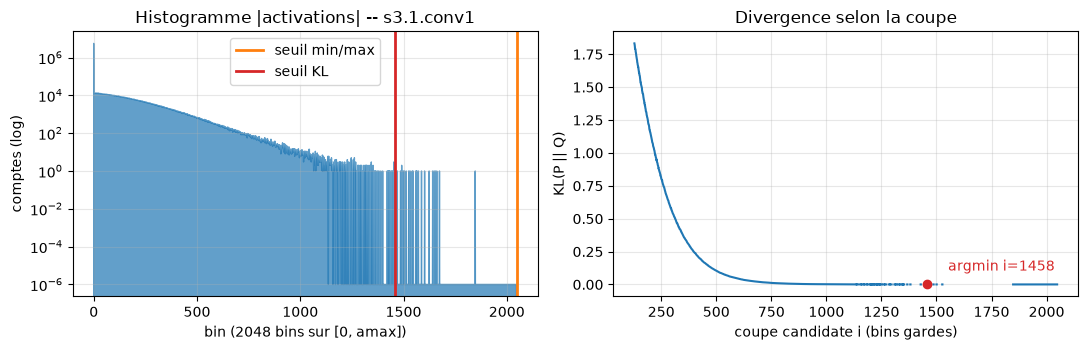

s3.1.conv1 : seuil KL = 71% du range min/max, masse coupee = 0.0003%


In [30]:
import matplotlib.pyplot as plt

name = "s3.1.conv1"
hist, amax = hists[name], totals[name]
i_star = int(scales_kl[name] / scales_mm[name] * NBINS)
curve = kl_curve(hist)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

ax1.fill_between(np.arange(NBINS), hist + 1e-6, color="tab:blue", alpha=0.7)
ax1.set_yscale("log")
ax1.axvline(NBINS, color="tab:orange", lw=2, label="seuil min/max")
ax1.axvline(i_star, color="tab:red", lw=2, label="seuil KL")
ax1.set_xlabel("bin (2048 bins sur [0, amax])")
ax1.set_ylabel("comptes (log)")
ax1.set_title(f"Histogramme |activations| -- {name}")
ax1.legend()

xs = np.arange(128, NBINS + 1)
ax2.plot(xs, curve, color="tab:blue")
ax2.scatter([i_star], [curve[i_star - 128]], color="tab:red", zorder=3)
ax2.annotate(f"argmin i={i_star}", (i_star, curve[i_star - 128]),
             textcoords="offset points", xytext=(15, 10), color="tab:red")
ax2.set_xlabel("coupe candidate i (bins gardes)")
ax2.set_ylabel("KL(P || Q)")
ax2.set_title("Divergence selon la coupe")
fig.tight_layout()
plt.show()

print(f"{name} : seuil KL = {i_star/NBINS:.0%} du range min/max, "
      f"masse coupee = {hist[i_star:].sum()/hist.sum():.4%}")

In [31]:
acc_st_kl = eval_static(model, test_loader, scales_kl, "channel")
print(f"[static KL toutes couches, w-channel] {acc_st_kl:.4f}  ({acc_fp32-acc_st_kl:+.4f})")

[static KL toutes couches, w-channel] 0.8989  (+0.0004)


**Lecture.** La calibration KL égalise le min/max (écart de 0,0002 sur ce run, dans le bruit de mesure) : en resserrant les seuils à 59-100 % du range (médiane 70 %), elle achète une résolution plus fine sur le corps des distributions — là où vit la masse — au prix d'un écrêtage de moins d'un centième de pourcent de la queue. C'est le comportement documenté de TensorRT : sur un CNN sain les deux calibrations sont interchangeables ; KL paie sur les réseaux aux activations à queue lourde.

**L'aside du stem.** Regardez la première ligne de la table : l'entrée du réseau choisit ~100 % du range. La raison est amusante et mesurable : l'entrée, c'est l'image normalisée — issue de pixels **8 bits**, donc ~768 valeurs distinctes. Son « histogramme continu » est en réalité un **peigne** (la plupart des bins au-delà du corps sont vides), et la moitié des coupes candidates tombent sur un trou du peigne → $Q = 0$ où $P > 0$ → divergence $+\infty$ → rejet. La calibration entropique n'a tout simplement pas de sens sur une donnée déjà discrète — dans un vrai pipeline INT8, l'entrée est quantifiée avec ses propres bornes (celles du capteur), pas calibrée par KL.


Réduisons encore : 15 codes par canal au lieu de 255 (7 niveaux positifs + signe). Les poids INT4 divisent encore la taille par deux — c'est le régime des LLM sur portables et du *QLoRA* rencontré dans la série FineTuning. Le même fake-quant, la même mesure :

## 19. La falaise INT4 : quinze codes au lieu de deux cent cinquante-cinq

Reste le cas extrême annoncé en tête de partie : **INT4**. Mêmes poids, même mapping affine, mais `2**4 = 16` niveaux au lieu de 256. Trois bits de moins — et la courbe ne descend pas, elle tombe.

In [32]:
def fakeq4_channel(w):
    scale = w.reshape(w.shape[0], -1).abs().amax(dim=1).clamp(min=1e-12) / 7.0
    scale = scale.view([-1] + [1] * (w.dim() - 1))
    return scale * torch.clamp(torch.round(w / scale), -8, 7)


def quantize_weights4(ref):
    m = copy.deepcopy(ref)
    with torch.no_grad():
        for mod in m.modules():
            if isinstance(mod, (nn.Conv2d, nn.Linear)):
                mod.weight.copy_(fakeq4_channel(mod.weight.detach()))
    return m


acc_w4 = evaluate(quantize_weights4(model), test_loader)
w4 = model.s3[1].conv1.weight.detach()
print(f"[INT4 poids seuls, per-channel sym] {acc_w4:.4f}  ({acc_fp32-acc_w4:+.4f})")
print(f"[erreur relative poids s3.1.conv1] INT4 : {relerr(w4, fakeq4_channel(w4)):.3e} "
      f"(vs INT8 per-channel : {relerr(w, fakeq_channel(w)):.3e})")

[INT4 poids seuls, per-channel sym] 0.8823  (+0.0170)
[erreur relative poids s3.1.conv1] INT4 : 1.431e-01 (vs INT8 per-channel : 7.886e-03)


**Lecture.** Voilà la falaise : 15 codes font perdre ~1,7 point, quand 255 n'en coûtaient aucun. L'erreur relative de quantification des poids monte d'un facteur ~18. La réponse industrielle à cette falaise n'est pas « plus de bits » mais **l'entraînement conscient de la quantification** (*quantization-aware training*, QAT) : quelques époques de fine-tuning où le forward passe par le fake-quant — le réseau apprend à vivre dans la grille. C'est le pont naturel vers la série PostTraining.

In [33]:
w_tot = sum(p.numel() for mod in model.modules()
            if isinstance(mod, (nn.Conv2d, nn.Linear)) for p in mod.parameters())
print(f"[taille] poids conv+fc : {w_tot:,}")
print(f"  FP32 : {w_tot*4/1e6:.2f} Mo   INT8 : {w_tot/1e6:.2f} Mo   "
      f"({w_tot*4/w_tot:.0f}x plus petit)   INT4 : {w_tot/2e6:.2f} Mo")
print()
print("=== RECAPITULATIF ===")
for lab, a in [("FP32", acc_fp32),
               ("w4 per-channel", acc_w4),
               ("w8 per-tensor", acc_wpt),
               ("w8 per-channel", acc_wpc),
               ("dynamic w-tensor", acc_dyn_t),
               ("dynamic w-channel", acc_dyn_c),
               ("static min/max w-channel", acc_st_mm),
               ("static KL w-channel", acc_st_kl)]:
    print(f"  {lab:<26} {a:.4f}  ({acc_fp32-a:+.4f})")

[taille] poids conv+fc : 270,906
  FP32 : 1.08 Mo   INT8 : 0.27 Mo   (4x plus petit)   INT4 : 0.14 Mo

=== RECAPITULATIF ===
  FP32                       0.8993  (+0.0000)
  w4 per-channel             0.8823  (+0.0170)
  w8 per-tensor              0.8984  (+0.0009)
  w8 per-channel             0.8987  (+0.0006)
  dynamic w-tensor           0.8978  (+0.0015)
  dynamic w-channel          0.8978  (+0.0015)
  static min/max w-channel   0.8987  (+0.0006)
  static KL w-channel        0.8989  (+0.0004)


## 20. Ce que la partie II a établi

1. **INT8 est essentiellement gratuit sur un CNN bien entraîné** — poids et activations, per-tensor ou per-channel, dynamique ou statique : toutes les configurations tiennent dans ±0,0015. Ce n'est pas la faiblesse du terrain : c'est le résultat industriel standard, et la raison pour laquelle l'INT8 est le régime par défaut du déploiement.
2. **La discrimination existe au niveau numérique, pas au niveau de l'exactitude** : per-channel divise l'erreur relative de poids par ~1,5 ; c'est la marge de sécurité de l'ingénieur, invisible dans le score.
3. **La calibration est un compromis quantitatif** : min/max n'écrête rien mais dilue la résolution ; KL coupe la queue (seuils à ~70 % du range en médiane, masse coupée ≤ 0,001 %) pour raffiner le corps — et s'égalise au min/max sur l'exactitude.
4. **La distribution doit être continue pour que KL ait un sens** : sur l'entrée 8 bits (histogramme en peigne), la moitié des coupes sont rejetées à $+\infty$ — l'algorithme lui-même signale le mauvais usage.
5. **La falaise est à INT4** : ~1,7 point perdu en post-training pur, pour 8× de compression. On la repousse avec du fine-tuning (QAT), pas avec plus de bits.

**Limites honnêtes.** Le fake-quant simule l'arithmétique mais ne délivre ni la mémoire divisée par 4 (les tenseurs restent des float32 dont les valeurs vivent dans la grille INT8), ni l'accélération (les convolutions restent float) : les deux viennent des backends entiers (`torch.quantization`, TensorRT, ONNX Runtime), qui consomment exactement les $(s, z)$ calibrés ici. La calibration 8 batchs suffit sur ce réseau ; les réseaux à sorties à queue lourde (détection) sont le terrain où KL domine vraiment min/max.

## 21. Exercices — partie II (entier)

Trois exercices qui prolongent les mesures de la partie II : chacun touche une décision
d'ingénierie réelle — où couper une distribution (percentile, contre min/max et contre KL),
comment le nombre de niveaux change ce choix, et quelles couches méritent de rester en haute
précision.

Rappel, identique à la partie I : une cellule d'exercice est un **squelette à compléter**,
jamais une erreur volontaire. Le carnet s'exécute de bout en bout sans vos réponses.

### Exercice 5 — Calibration par percentile

Min/max suit les outliers ; KL optimise un critère de distribution. Entre les deux, la calibration **percentile** : écrêter tout ce qui dépasse le p-ième percentile de la masse. À votre tour de la calibrer — puis de la comparer aux deux autres sur l'exactitude.

**Objectif** : écrire `scales_percentile(hists, totals, p)`, renvoyant le même format que `scales_mm`. **Question** : à p = 99,9 %, tombe-t-on côté min/max ou côté KL ?

In [34]:
def scales_percentile(hists, totals, p=99.9):
    # TODO etudiant : renvoyer {nom: scale} ou le seuil est le p-ieme percentile
    # de l'histogramme de la couche (masse cumulee p%), pas le max absolu.
    # Indice : np.cumsum(hist) / hist.sum() donne la masse cumulee bin par bin.
    # Etape 1 : construire la cumsum normalisee.
    # Etape 2 : trouver le premier bin ou elle depasse p (np.searchsorted).
    # Etape 3 : convertir en seuil (amax * bin / NBINS) puis en scale (/ 127).
    return None  # TODO etudiant


scales_p999 = scales_percentile(hists, totals, p=99.9)
if scales_p999 is not None:
    acc_p999 = eval_static(model, test_loader, scales_p999, "channel")
    print(f"[static percentile 99.9, w-channel] {acc_p999:.4f}  ({acc_fp32-acc_p999:+.4f})")
    print(f"  (a comparer : min/max {acc_st_mm:.4f}, KL {acc_st_kl:.4f})")
else:
    print("Exercice a completer")

Exercice a completer


### Exercice 6 — KL à 64 niveaux

La calibration KL dépend du nombre de niveaux de la grille cible. Refaites la recherche pour une cible **64 niveaux** sur la couche `fc` et comparez le seuil choisi. **Question** : le seuil monte-t-il ou descend-il, et pourquoi ? (Indice : moins de niveaux = chaque niveau compte plus... la réponse n'est pas intuitive avant de l'avoir mesurée.)

In [35]:
def kl_threshold_64(hist, amax, nbins=NBINS):
    # TODO etudiant : meme recherche que kl_threshold, mais la cible de
    # quantification a 64 niveaux (levels=64) au lieu de 128.
    # Indice : kl_curve accepte levels= en parametre.
    # Etape 1 : appel de kl_curve avec la bonne cible.
    # Etape 2 : recuperer le DERNIER argmin (egalites -> seuil le plus grand).
    return None  # TODO etudiant


t64 = kl_threshold_64(hists["fc"], totals["fc"])
if t64 is not None:
    t128 = kl_threshold(hists["fc"], totals["fc"])
    print(f"fc : seuil KL 128 niveaux = {t128:.4f}  |  64 niveaux = {t64:.4f}  "
          f"({t64/t128:.0%})")
else:
    print("Exercice a completer")

Exercice a completer

### Exercice 7 — Sensibilité par étage

Toutes les couches ne souffrent pas également de la quantification. Le diagnostic classique : appliquer la quantification statique à **un étage à la fois** (les autres en FP32) et classer les étages par chute d'exactitude — c'est la *layer-wise sensitivity analysis*, qui décide où investir en précision mixte.

**Objectif** : écrire `sensibilite_par_etage(scales)` renvoyant `{etage: exactitude}` pour `s1`, `s2`, `s3`. **Question** : la dégradation est-elle uniforme, ou un étage concentre-t-il la sensibilité ?

In [36]:
def sensibilite_par_etage(scales, stages=("s1", "s2", "s3")):
    # TODO etudiant : pour chaque etage, evaluer l'exactitude avec la quantification
    # statique appliquee a CET ETAGE SEUL (les autres couches en FP32).
    # Renvoyer {etage: exactitude}.
    # Indice : eval_static accepte un dict de scales -- donnez-lui seulement les
    # couches de l'etage : {n: s for n, s in scales.items() if n.startswith(etage)}.
    # Etape 1 : filtrer les scales de l'etage.
    # Etape 2 : appeler eval_static avec ce sous-ensemble.
    # Etape 3 : boucler sur les trois etages.
    return None  # TODO etudiant


sens = sensibilite_par_etage(scales_mm)
if sens is not None:
    for st, a in sorted(sens.items()):
        print(f"  {st} seul : {a:.4f}  ({acc_fp32-a:+.4f})")
else:
    print("Exercice a completer")

Exercice a completer


## Conclusion

Le carnet a réduit les nombres du même réseau par les deux axes de la quantification
post-training, et la comparaison des deux est le résultat le plus utile.

**Partie I — réduire la largeur du format.** FP32 → FP16 / BF16 s'écrit à la main en trois
champs. La troncature coûte un facteur 2 en erreur face à l'arrondi ($2^{-10}$ contre $2^{-11}$
en FP16), et son biais est systématique **en signe** ; FP16 et BF16 ne cassent pas au même
endroit — FP16 s'effondre sous $6\times10^{-8}$ et déborde à 65504, BF16 garde la plage de
FP32 au prix de sa mantisse. Le choix est un arbitrage **portée contre précision**, dicté par
la distribution des valeurs. Et l'accumulation est un axe distinct : convertir les entrées
coûte $\sim10^{-4}$, accumuler en FP16 plutôt qu'en FP32 coûte plusieurs ordres de grandeur de
plus.

**Partie II — réduire le nombre de niveaux.** Sur un ResNet-20 bien entraîné, l'INT8 est
essentiellement gratuit : poids et activations, per-tensor ou per-channel, dynamique ou
statique, toutes les configurations tiennent dans ±0,0015. La discrimination existe au niveau
numérique — le per-channel divise l'erreur relative des poids par ~1,5 — mais reste invisible
dans le score : c'est la marge de sécurité de l'ingénieur. La calibration est un compromis
quantitatif, où KL échange un écrêtage de moins d'un centième de pourcent contre une
résolution plus fine sur le corps des distributions. La falaise est à **INT4** : ~1,7 point perdu en post-training pur, pour 8× de compression — on la repousse par l'entraînement
conscient de la quantification, pas par des bits supplémentaires.

**Le pont entre les deux parties.** La mise à l'échelle de l'exercice 4 *est* le `scale` de la
partie II : décaler avant de convertir pour ne pas gaspiller la résolution. La partie II ajoute
ce dont le flottant n'a pas besoin — le `zero-point`, qui absorbe l'asymétrie d'une plage
d'activations, et la calibration, qui choisit la plage sans jamais voir les données de test.

**Limites honnêtes.** La partie II est une *fake quantification* : elle simule l'arithmétique
mais ne délivre ni la mémoire divisée par 4, ni l'accélération — les deux viennent des backends
entiers, qui consomment exactement les $(s, z)$ calibrés ici. La partie I, elle, reste de la
conversion de format : elle ne compresse pas un réseau, elle réduit la taille de ce qu'il
stocke. Les deux mesurent leurs pertes, aucune ne prétend aller plus loin.

### Où cela s'inscrit dans le panorama

| Bloc | Carnet | Sujet | État |
|---|---|---|---|
| A.1 | **3.9, partie I** (ce carnet) | FP32 → FP16/BF16, from scratch | livré |
| A.2 | **3.9, partie II** (ce carnet) | INT8 dynamic et static, scale + zero-point, calibration KL, INT4 | livré |
| A.3 | `3.9b` / `3.9c` | élagage from scratch : magnitude non structuré, filtres structurés, LTH | livré |
| A.4 | `3.7` | distillation teacher/student, ResNet-20 → ResNet-8 sur CIFAR-10 | livré |
| B.2 | `3.9e` | les mêmes techniques par l'écosystème PyTorch (`torch.ao.quantization`, `torch.nn.utils.prune`) | livré |
| 7 | `3.9g` | comparatif capstone A vs B (accuracy, taille brute + zlib, latence CPU, FLOPs, LOC) | livré |

## Pour aller plus loin

- [3.7 — Distillation maître-élève](3.7-Distillation-Maitre-Eleve.ipynb) : l'autre axe de compression (le savoir, pas les nombres) — les deux se combinent.
- Série **PostTraining** : la version industrielle de ce notebook — vraies représentations INT8/INT4, kernels quantifiés, QAT.
- Série **FineTuning** ([FT-00a](../../../GenAI/FineTuning/FT-00a-LoRA-from-scratch-Python.ipynb)) : le *QLoRA* y rencontre la falaise INT4 de la section 19 — et l'utilise.

**Environnement** : kernel `python3` (torch + torchvision + matplotlib). L'entraînement complet exige un GPU (~8 min sur RTX 3090) ; sur CPU le notebook s'exécute avec une recette réduite (6 époques).